In [1]:

%pip install -q numpy pandas matplotlib scikit-learn scikit-image opencv-python pillow tensorflow joblib


Note: you may need to restart the kernel to use updated packages.


In [2]:

import os
import zipfile
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from PIL import Image, ImageOps
from skimage.feature import hog

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


TensorFlow version: 2.21.0
GPU available: False


In [7]:

DATA_DIR = Path(r"C:\Users\Lenovo\Downloads\ann note dataset")
ZIP_PATH = Path(r"C:\Users\Lenovo\Downloads\ann note dataset")

print("Dataset path:", DATA_DIR.resolve())
print("Dataset exists:", DATA_DIR.exists())


Dataset path: C:\Users\Lenovo\Downloads\ann note dataset
Dataset exists: True


In [8]:

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not DATA_DIR.exists():
    raise FileNotFoundError(
        "Create currency_dataset/ and add denomination folders."
    )

paths = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

if not paths:
    raise ValueError("No images found in the dataset.")

df = pd.DataFrame({
    "path": [str(p) for p in paths],
    "label": [p.parent.name for p in paths]
})

print("Total images:", len(df))
print("Denominations:", sorted(df["label"].unique()))

display(df["label"].value_counts().sort_index().to_frame("image_count"))


Total images: 2679
Denominations: ['fifty_new', 'fifty_old', 'five_hundred', 'hundred_new', 'hundred_old', 'ten_new', 'ten_old', 'twenty_new', 'twenty_old', 'two_hundred', 'two_thousand']


,image_count
label,
fifty_new,265
fifty_old,234
five_hundred,279
hundred_new,224
hundred_old,107
ten_new,345
ten_old,306
twenty_new,288
twenty_old,257


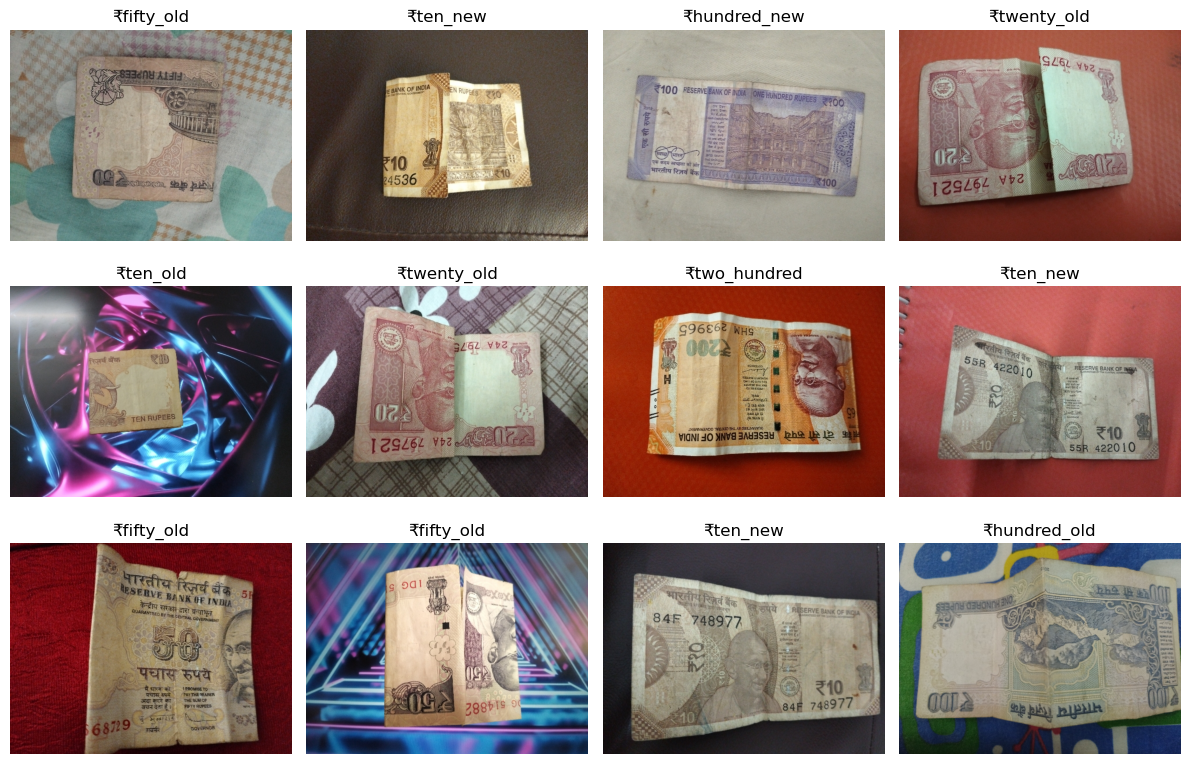

In [9]:

sample = df.sample(min(12, len(df)), random_state=SEED)

fig, axes = plt.subplots(3, 4, figsize=(12, 8))

for ax in axes.flat:
    ax.axis("off")

for ax, row in zip(axes.flat, sample.itertuples(index=False)):
    ax.imshow(Image.open(row.path).convert("RGB"))
    ax.set_title(f"₹{row.label}")

plt.tight_layout()
plt.show()


In [10]:

label_encoder = LabelEncoder()

df["label_id"] = label_encoder.fit_transform(
    df["label"].astype(str)
)

class_names = list(label_encoder.classes_)
num_classes = len(class_names)

if num_classes < 2:
    raise ValueError("At least two denomination classes are required.")

if df["label_id"].value_counts().min() < 10:
    raise ValueError(
        "Each denomination needs at least 10 images."
    )

train_val_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["label_id"]
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_val_df["label_id"]
)

print("Classes:", class_names)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))


Classes: ['fifty_new', 'fifty_old', 'five_hundred', 'hundred_new', 'hundred_old', 'ten_new', 'ten_old', 'twenty_new', 'twenty_old', 'two_hundred', 'two_thousand']
Training images: 1714
Validation images: 429
Testing images: 536


In [11]:

IMG_SIZE = (128, 128)

def load_rgb(path, size=IMG_SIZE):
    image = Image.open(path).convert("RGB")

    image = ImageOps.fit(
        image,
        size,
        method=Image.Resampling.LANCZOS
    )

    return np.asarray(image)


def extract_ann_features(path):
    rgb = load_rgb(path)

    features = []

    # RGB colour histograms
    for channel in range(3):
        hist, _ = np.histogram(
            rgb[:, :, channel],
            bins=16,
            range=(0, 256),
            density=True
        )

        features.extend(hist.astype(np.float32))

    # Shape and edge features
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    hog_features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    return np.concatenate([
        np.asarray(features, dtype=np.float32),
        hog_features
    ])


def make_ann_data(frame):
    X = np.vstack([
        extract_ann_features(path)
        for path in frame["path"]
    ])

    y = frame["label_id"].to_numpy(dtype=np.int64)

    return X, y


X_train_ann, y_train = make_ann_data(train_df)
X_val_ann, y_val = make_ann_data(val_df)
X_test_ann, y_test = make_ann_data(test_df)

print("ANN training feature shape:", X_train_ann.shape)


ANN training feature shape: (1714, 1812)


In [12]:

ann_model = Pipeline([
    ("scaler", StandardScaler()),

    ("mlp", MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        max_iter=50,
        early_stopping=True,
        n_iter_no_change=6,
        random_state=SEED,
        verbose=True
    ))
])

ann_model.fit(X_train_ann, y_train)

ann_val_pred = ann_model.predict(X_val_ann)

ann_val_accuracy = accuracy_score(
    y_val,
    ann_val_pred
)

print("ANN validation accuracy:", round(ann_val_accuracy, 4))


Iteration 1, loss = 2.42806146
Validation score: 0.261628
Iteration 2, loss = 1.53190456
Validation score: 0.319767
Iteration 3, loss = 1.06811718
Validation score: 0.313953
Iteration 4, loss = 0.72534145
Validation score: 0.296512
Iteration 5, loss = 0.47377865
Validation score: 0.354651
Iteration 6, loss = 0.29785253
Validation score: 0.337209
Iteration 7, loss = 0.18661806
Validation score: 0.343023
Iteration 8, loss = 0.11611077
Validation score: 0.343023
Iteration 9, loss = 0.07618562
Validation score: 0.337209
Iteration 10, loss = 0.05316753
Validation score: 0.337209
Iteration 11, loss = 0.03914726
Validation score: 0.343023
Iteration 12, loss = 0.03038524
Validation score: 0.348837
Validation score did not improve more than tol=0.000100 for 6 consecutive epochs. Stopping.
ANN validation accuracy: 0.3846


In [13]:

RNN_HEIGHT = 64
RNN_WIDTH = 64

def image_to_sequence(path):
    image = Image.open(path).convert("RGB")

    image = ImageOps.fit(
        image,
        (RNN_WIDTH, RNN_HEIGHT),
        method=Image.Resampling.LANCZOS
    )

    arr = np.asarray(image, dtype=np.float32) / 255.0

    # 64 time steps; each row has 64 * 3 features
    return arr.reshape(RNN_HEIGHT, RNN_WIDTH * 3)


def make_rnn_data(frame):
    X = np.stack([
        image_to_sequence(path)
        for path in frame["path"]
    ])

    y = frame["label_id"].to_numpy(dtype=np.int64)

    return X, y


X_train_rnn, y_train_rnn = make_rnn_data(train_df)
X_val_rnn, y_val_rnn = make_rnn_data(val_df)
X_test_rnn, y_test_rnn = make_rnn_data(test_df)

print("RNN training shape:", X_train_rnn.shape)
print("RNN validation shape:", X_val_rnn.shape)
print("RNN testing shape:", X_test_rnn.shape)


RNN training shape: (1714, 64, 192)
RNN validation shape: (429, 64, 192)
RNN testing shape: (536, 64, 192)


In [14]:

rnn_model = keras.Sequential([
    layers.Input(shape=(RNN_HEIGHT, RNN_WIDTH * 3)),

    layers.LSTM(64),

    layers.Dropout(0.3),

    layers.Dense(64, activation="relu"),

    layers.Dense(num_classes, activation="softmax")
])

rnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

rnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 11)                  │             715 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 70,667 (276.04 KB)

 Trainable params: 70,667 (276.04 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=2,
        factor=0.5,
        min_lr=1e-6
    )
]

rnn_history = rnn_model.fit(
    X_train_rnn,
    y_train_rnn,
    validation_data=(X_val_rnn, y_val_rnn),
    epochs=20,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 0.1295 - loss: 2.3670 - val_accuracy: 0.1469 - val_loss: 2.3248 - learning_rate: 0.0010
Epoch 2/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.1540 - loss: 2.3285 - val_accuracy: 0.1865 - val_loss: 2.2969 - learning_rate: 0.0010
Epoch 3/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.1529 - loss: 2.3069 - val_accuracy: 0.1748 - val_loss: 2.2808 - learning_rate: 0.0010
Epoch 4/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.1692 - loss: 2.2820 - val_accuracy: 0.1795 - val_loss: 2.2490 - learning_rate: 0.0010
Epoch 5/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.1902 - loss: 2.2506 - val_accuracy: 0.2191 - val_loss: 2.2240 - learning_rate: 0.0010
Epoch 6/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.1756 - loss: 2.2488 - val_accuracy: 0.2005 - val_loss: 2.2313 - learning_rate: 0.0010
Epoch 7/20
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.1914 - loss: 2.2161 - val_acc

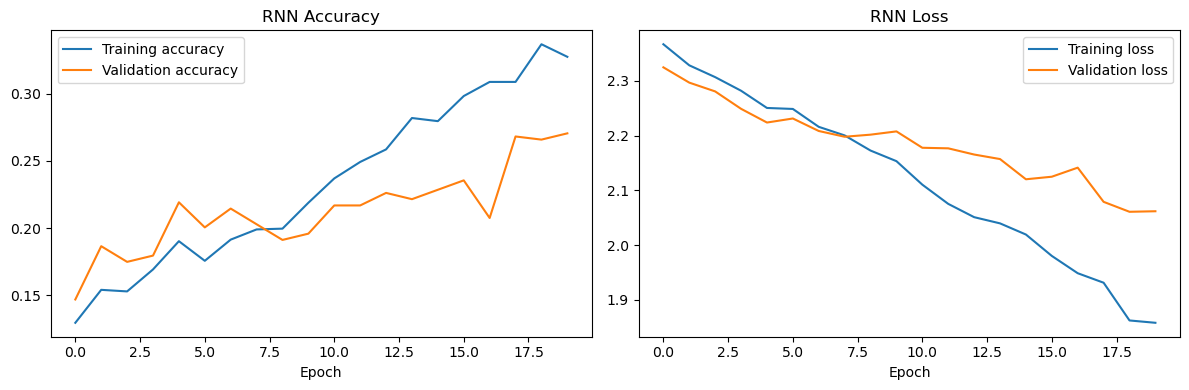

In [16]:

hist = pd.DataFrame(rnn_history.history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist["accuracy"], label="Training accuracy")
axes[0].plot(hist["val_accuracy"], label="Validation accuracy")
axes[0].set_title("RNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(hist["loss"], label="Training loss")
axes[1].plot(hist["val_loss"], label="Validation loss")
axes[1].set_title("RNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


In [17]:

ann_test_pred = ann_model.predict(X_test_ann)

rnn_prob = rnn_model.predict(
    X_test_rnn,
    verbose=0
)

rnn_test_pred = np.argmax(rnn_prob, axis=1)

ann_acc = accuracy_score(y_test, ann_test_pred)
rnn_acc = accuracy_score(y_test_rnn, rnn_test_pred)

results = pd.DataFrame({
    "Model": [
        "ANN (MLP)",
        "RNN (LSTM)"
    ],
    "Test Accuracy": [
        ann_acc,
        rnn_acc
    ]
})

display(results)

print("\nANN classification report:")
print(classification_report(
    y_test,
    ann_test_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0
))

print("\nRNN classification report:")
print(classification_report(
    y_test_rnn,
    rnn_test_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0
))


,Model,Test Accuracy
0,ANN (MLP),0.395522
1,RNN (LSTM),0.305970



ANN classification report:
              precision    recall  f1-score   support

   fifty_new       0.36      0.30      0.33        53
   fifty_old       0.43      0.38      0.40        47
five_hundred       0.42      0.45      0.43        56
 hundred_new       0.31      0.31      0.31        45
 hundred_old       0.30      0.14      0.19        21
     ten_new       0.36      0.42      0.39        69
     ten_old       0.39      0.46      0.42        61
  twenty_new       0.33      0.29      0.31        58
  twenty_old       0.39      0.49      0.43        51
 two_hundred       0.49      0.47      0.48        55
two_thousand       0.85      0.55      0.67        20

    accuracy                           0.40       536
   macro avg       0.42      0.39      0.40       536
weighted avg       0.40      0.40      0.39       536


RNN classification report:
              precision    recall  f1-score   support

   fifty_new       0.49      0.57      0.53        53
   fifty_old       0.2

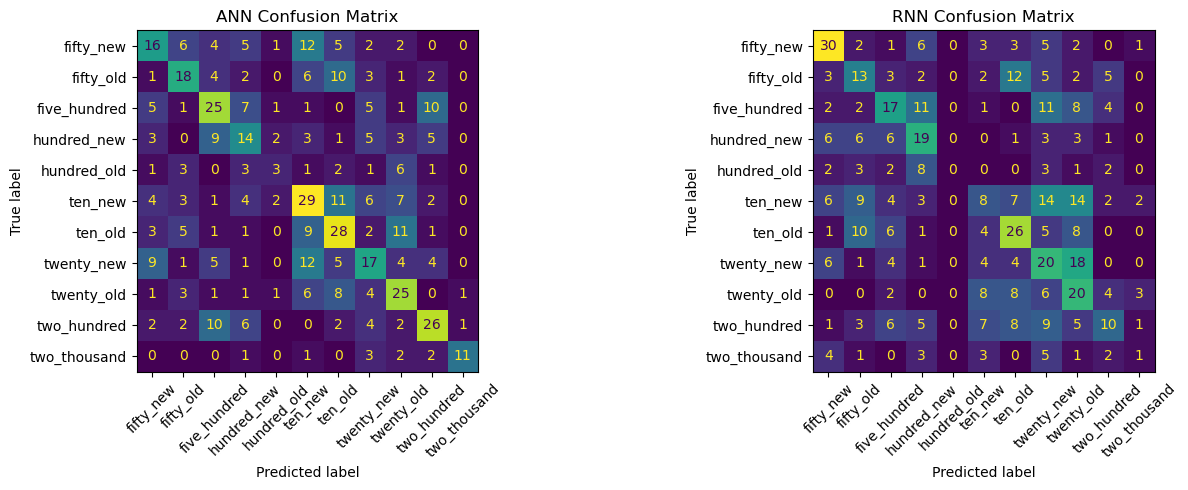

In [18]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    ann_test_pred,
    labels=np.arange(num_classes),
    display_labels=class_names,
    xticks_rotation=45,
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("ANN Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test_rnn,
    rnn_test_pred,
    labels=np.arange(num_classes),
    display_labels=class_names,
    xticks_rotation=45,
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("RNN Confusion Matrix")

plt.tight_layout()
plt.show()


In [19]:

def predict_currency(image_path):
    image_path = Path(image_path)

    if not image_path.exists():
        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    # ANN prediction
    ann_x = extract_ann_features(image_path).reshape(1, -1)

    ann_probs = ann_model.predict_proba(ann_x)[0]
    ann_id = int(np.argmax(ann_probs))
    ann_conf = float(ann_probs[ann_id])

    # RNN prediction
    rnn_x = image_to_sequence(image_path)[None, ...]

    rnn_probs = rnn_model.predict(
        rnn_x,
        verbose=0
    )[0]

    rnn_id = int(np.argmax(rnn_probs))
    rnn_conf = float(rnn_probs[rnn_id])

    # Display image
    plt.figure(figsize=(6, 4))
    plt.imshow(Image.open(image_path).convert("RGB"))
    plt.axis("off")
    plt.show()

    print("ANN predicted denomination: ₹", class_names[ann_id])
    print(f"ANN model score: {ann_conf:.1%}")

    print("RNN predicted denomination: ₹", class_names[rnn_id])
    print(f"RNN model score: {rnn_conf:.1%}")

    print("Authenticity: NOT VERIFIED")
    print("This model does not confirm whether the note is genuine.")

    return {
        "ANN denomination": class_names[ann_id],
        "ANN score": ann_conf,
        "RNN denomination": class_names[rnn_id],
        "RNN score": rnn_conf,
        "Authenticity": "Not verified"
    }


Selected image: C:/Users/Lenovo/Downloads/ann note dataset/Datasets/two_thousand/IMG_1667830635659.jpg
File exists: True


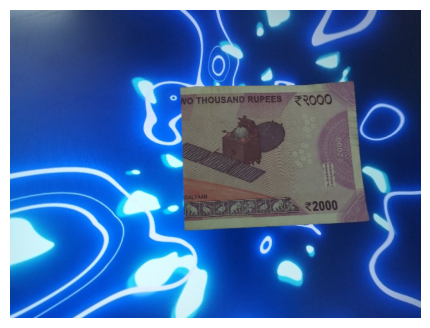

ANN predicted denomination: ₹ two_thousand
ANN model score: 98.7%
RNN predicted denomination: ₹ two_thousand
RNN model score: 37.8%
Authenticity: NOT VERIFIED
This model does not confirm whether the note is genuine.


In [30]:

from tkinter import Tk, filedialog
from pathlib import Path

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

image_path = filedialog.askopenfilename(
    title="Select an Indian Currency Image",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp *.webp"),
        ("All files", "*.*")
    ]
)

root.destroy()

if image_path:
    print("Selected image:", image_path)
    print("File exists:", Path(image_path).is_file())
    predict_currency(image_path)
else:
    print("No image selected.")


In [31]:

from pathlib import Path
import numpy as np
from PIL import Image
import tensorflow as tf
import joblib

MODEL_PATH = Path("rnn_currency_model.keras")
ENCODER_PATH = Path("label_encoder.joblib")

assert MODEL_PATH.exists(), f"Model file not found: {MODEL_PATH.resolve()}"
assert ENCODER_PATH.exists(), f"Label encoder not found: {ENCODER_PATH.resolve()}"

rnn_model = tf.keras.models.load_model(MODEL_PATH)
label_encoder = joblib.load(ENCODER_PATH)

print("RNN model loaded successfully.")
print("Classes learned:", list(label_encoder.classes_))
print("Model input shape:", rnn_model.input_shape)


AssertionError: Model file not found: C:\Users\Lenovo\rnn_currency_model.keras